In [1]:
import os
from pathlib import Path

# 1. Configuración de entorno y dependencias (Importaciones unificadas)
os.environ['DYLD_LIBRARY_PATH'] = '/opt/homebrew/opt/libomp/lib'
os.environ['LDFLAGS'] = '-L/opt/homebrew/opt/libomp/lib'
os.environ['CPPFLAGS'] = '-I/opt/homebrew/opt/libomp/include'

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV, PredefinedSplit

# 2. Carga de Datos y Verificación Inicial
DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS / 'data' / 'plata'
DATA_ADRESS = DATA_DIR / 'viajes_foraneos_oro.csv'

In [2]:
# Propósito: Importar librerías y cargar la capa oro.
import pandas as pd
import numpy as np
from pathlib import Path
import os
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

DS_FILE_ADRESS = Path()
DATA_DIR = DS_FILE_ADRESS/'data'/'plata'
DATA_ADRESS = DATA_DIR/'viajes_foraneos_oro.csv'

# Cargar los datos
df = pd.read_csv(DATA_ADRESS)

print("Columnas:", df.columns.tolist())
if 'Placas' in df.columns:
    print("\nEjemplo de datos:")
    print(df[['ID_VIAJE', 'Placas', 'PLANTA_ORIGEN', 'Ciudad Destino', 'FECHA_EGRESO', 'FECHA_VIAJE_FINALIZADO']].head())
    

Columnas: ['ID_VIAJE', 'Ciudad Destino', 'ID Camión', 'Tipo Camión', 'Programado (Peso)', 'PLANTA_ORIGEN', 'GRUPO_PLANTA_ORIGEN', 'FECHA_EGRESO', 'FAMILIA_CAMION_DESC', 'FECHA_VIAJE_FINALIZADO', 'Planta Origen', 'Transportista', 'Desc TpoTrn', 'Peso Total', 'Monto total', 'Placas', 'Tiempo_Viaje_Horas', 'Programado_kg', 'Discrepancia_Peso_kg', 'Ineficiencia_Capacidad', 'Nomenclatura_Inferida', 'Capacidad_Max_kg', 'Porcentaje_Utilizacion_Real', 'Capacidad_Sobra_kg', 'Toneladas_Reales', 'Toneladas_Maximas', 'Costo_Ton_Real', 'Costo_Ton_Optimo', 'Sobrecosto_Ton', 'Kilometros_Ruta', 'Tonelada_Kilometro', 'Costo_Ton_Km', 'Unnamed: 32', 'Unnamed: 33', 'Conteo de portacintas', 'Conteo de Big Coil']

Ejemplo de datos:
   ID_VIAJE  Placas PLANTA_ORIGEN Ciudad Destino    FECHA_EGRESO  \
0  73520731  66AF7U      Guerrero      Tultitlán  1/8/2026 16:57   
1  73550402  748AG5      Guerrero    Guadalajara  1/7/2026 11:06   
2  73605053  99AL6N      Guerrero      Tultitlán  1/9/2026 17:33   
3  73621

In [3]:
# 3. Preprocesamiento y Análisis de Consolidación
df = df.dropna(subset=['Placas']).copy()
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['FECHA_VIAJE_FINALIZADO'] = pd.to_datetime(df['FECHA_VIAJE_FINALIZADO'])

consolidacion = df.groupby(['Placas', 'FECHA_EGRESO']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Destinos_Lista=('Ciudad Destino', lambda x: list(set(x))),
    Total_Toneladas=('Toneladas_Reales', 'sum'),
    Capacidad_Max=('Capacidad_Max_kg', 'max')
).reset_index()

consolidados_reales = consolidacion[consolidacion['Destinos_Unicos'] > 1]
print(f"Viajes consolidados (misma placa, misma fecha, distinto destino): {len(consolidados_reales)}")

if len(consolidados_reales) > 0:
    print(consolidados_reales.head(3))
    
df['Dia_Egreso'] = df['FECHA_EGRESO'].dt.date
cons_dia = df.groupby(['Placas', 'Dia_Egreso']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Toneladas=('Toneladas_Reales', 'sum'),
    Cap_Max=('Capacidad_Max_kg', 'max')
).reset_index()

cons_dia_validos = cons_dia[(cons_dia['Destinos_Unicos'] > 1) & (cons_dia['Toneladas'] <= (cons_dia['Cap_Max']/1000))]
print(f"Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): {len(cons_dia_validos)}")

Viajes consolidados (misma placa, misma fecha, distinto destino): 0
Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): 4


Viajes consolidados (misma placa, misma fecha, distinto destino): 0
Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): 4

Total de conexiones entre viajes analizadas: 53056
Estadísticas de horas de espera entre un viaje y otro de la misma placa:
count    53056.000000
mean        85.328247
std        281.865828
min       -214.550000
25%          0.000000
50%         20.900000
75%         77.170833
max       5298.200000
Name: Horas_Espera_Nuevo_Viaje, dtype: float64
Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): 28005

Camión regresó y cargó de nuevo en la misma Planta de Origen: 54.4% de las veces


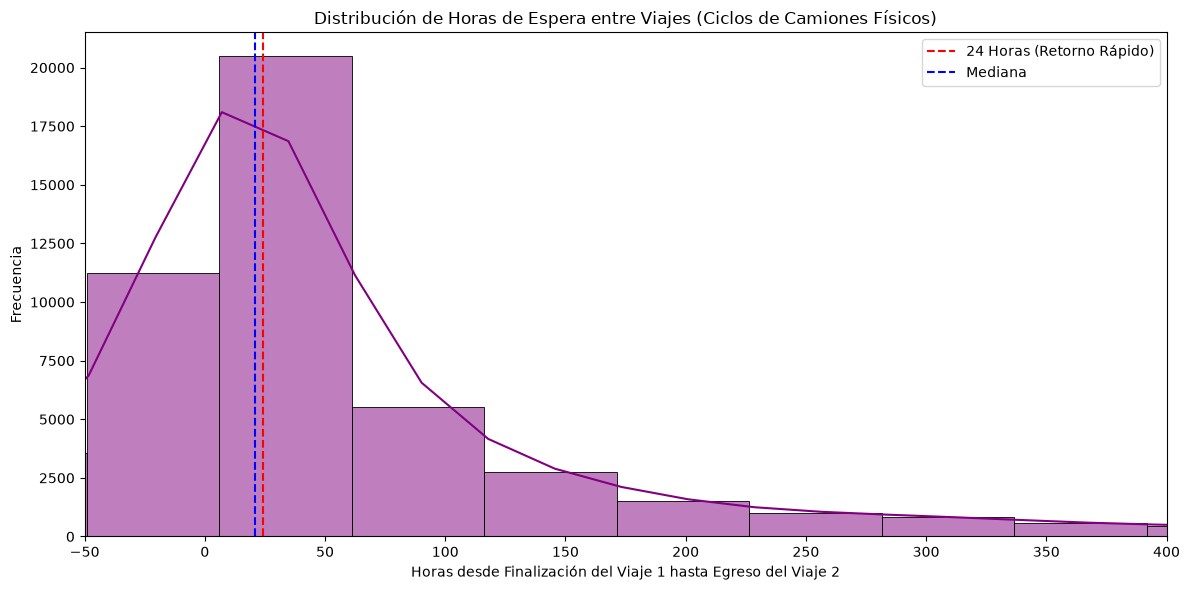

In [4]:
# Propósito: Consolidación (misma placa, mismo día, distinto destino) y ciclos entre viajes consecutivos de una placa (posibles regresos).
# Filtrar nulos en Placas
df = df.dropna(subset=['Placas']).copy()

# Convertir fechas
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['FECHA_VIAJE_FINALIZADO'] = pd.to_datetime(df['FECHA_VIAJE_FINALIZADO'])

# ANÁLISIS DE CONSOLIDACIÓN (Misma Placa, Misma Fecha, Distinto Destino)
# Agrupamos por Placa y Fecha de Egreso exacta (o podríamos usar ventana de 1 hr)
consolidacion = df.groupby(['Placas', 'FECHA_EGRESO']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Destinos_Lista=('Ciudad Destino', lambda x: list(set(x))),
    Total_Toneladas=('Toneladas_Reales', 'sum'),
    Capacidad_Max=('Capacidad_Max_kg', 'max') # Asumiendo misma placa = misma capacidad
).reset_index()

# Filtramos aquellos con >1 destino en el mismo minuto
consolidados_reales = consolidacion[consolidacion['Destinos_Unicos'] > 1]
print(f"Viajes consolidados (misma placa, misma fecha, distinto destino): {len(consolidados_reales)}")

if len(consolidados_reales) > 0:
    print(consolidados_reales.head(3))
    
# ¿Qué pasa si relajamos a "mismo día"?
df['Dia_Egreso'] = df['FECHA_EGRESO'].dt.date
cons_dia = df.groupby(['Placas', 'Dia_Egreso']).agg(
    Viajes=('ID_VIAJE', 'count'),
    Destinos_Unicos=('Ciudad Destino', 'nunique'),
    Toneladas=('Toneladas_Reales', 'sum'),
    Cap_Max=('Capacidad_Max_kg', 'max')
).reset_index()

cons_dia_validos = cons_dia[(cons_dia['Destinos_Unicos'] > 1) & (cons_dia['Toneladas'] <= (cons_dia['Cap_Max']/1000))]
print(f"Viajes consolidados (misma placa, mismo DÍA, distinto destino y caben físicamente): {len(cons_dia_validos)}")


# ANÁLISIS DE BACKHAUL Y CICLOS
# Ordenamos cronológicamente el historial de cada placa
# 4. Análisis de Backhaul y Ciclos
df = df.sort_values(['Placas', 'FECHA_EGRESO']).reset_index(drop=True)

df['Siguiente_Placa'] = df['Placas'].shift(-1)
df['Siguiente_Origen'] = df['PLANTA_ORIGEN'].shift(-1)
df['Siguiente_Egreso'] = df['FECHA_EGRESO'].shift(-1)
df['Siguiente_Destino'] = df['Ciudad Destino'].shift(-1)

df['Es_Misma_Placa'] = (df['Placas'] == df['Siguiente_Placa'])
df['Horas_Espera_Nuevo_Viaje'] = np.where(
    df['Es_Misma_Placa'], 
    (df['Siguiente_Egreso'] - df['FECHA_VIAJE_FINALIZADO']).dt.total_seconds() / 3600, 
    np.nan
)

viajes_secuenciales = df[df['Es_Misma_Placa']].copy()

print(f"\nTotal de conexiones entre viajes analizadas: {len(viajes_secuenciales)}")
print("Estadísticas de horas de espera entre un viaje y otro de la misma placa:")
print(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].describe())

backhauls_potenciales = viajes_secuenciales[viajes_secuenciales['Horas_Espera_Nuevo_Viaje'] <= 24]
print(f"Viajes con espera menor a 24h (Potencial Backhaul o triángulo eficiente): {len(backhauls_potenciales)}")

# Generación de la gráfica
plt.figure(figsize=(12, 6))
sns.histplot(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].dropna(), bins=100, color='purple', kde=True)
plt.xlim(-50, 400)
plt.axvline(24, color='red', linestyle='--', label='24 Horas (Retorno Rápido)')
plt.axvline(viajes_secuenciales['Horas_Espera_Nuevo_Viaje'].median(), color='blue', linestyle='--', label='Mediana')
plt.title('Distribución de Horas de Espera entre Viajes (Ciclos de Camiones Físicos)')
plt.xlabel('Horas desde Finalización del Viaje 1 hasta Egreso del Viaje 2')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
#plt.savefig('ciclos_placas.png')
#print("Gráfica ciclos_placas.png generada.")

viajes_secuenciales['Retorno_A_Base'] = viajes_secuenciales['PLANTA_ORIGEN'] == viajes_secuenciales['Siguiente_Origen']
print(f"\nCamión regresó y cargó de nuevo en la misma Planta de Origen: {viajes_secuenciales['Retorno_A_Base'].mean()*100:.1f}% de las veces")

In [5]:
# 5. Preparación de variables para el Modelo Econométrico
df = df.rename(columns={
    'Monto total': 'Costo',
    'Programado_kg': 'Peso_Programado',
    'Ciudad Destino': 'Destino'
})

df['Ruta'] = df['PLANTA_ORIGEN'] + "_" + df['Destino']

mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])

mapeo_camiones = {
    'T3-S2-R4 (Full)': 'Full',
    'T3-S3 (3 Ejes)': 'Tres_Ejes',
    'T3-S2 (2 Ejes)': 'Dos_Ejes',
    'Torton': 'Torton',
    'T3_S3_Portacintas': 'Portacintas'
}
df['Camion'] = df['Camion'].map(mapeo_camiones)

df_reg = df.dropna(subset=['Costo', 'Peso_Programado', 'Camion', 'Ruta']).copy()
top_rutas = df_reg['Ruta'].value_counts().head(50).index 
df_model = df_reg[df_reg['Ruta'].isin(top_rutas)].copy()

print(f"Viajes en las Top 50 Rutas: {len(df_model)}")

Viajes en las Top 50 Rutas: 31803


In [6]:
# Propósito: Regresión OLS: efecto del tipo de camión sobre el costo, controlando por peso y ruta (top 50 rutas).
# Unificar nombres de columnas para que statsmodels no tenga problemas
df = df.rename(columns={
    'Monto total': 'Costo',
    'Programado_kg': 'Peso_Programado',
    'Ciudad Destino': 'Destino'
})

# Crear la variable de Ruta (Efecto Fijo principal)
df['Ruta'] = df['PLANTA_ORIGEN'] + "_" + df['Destino']

# Asegurar la correcta nomenclatura de los camiones de interés
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])

# Limpiar nombres de camiones para la fórmula
mapeo_camiones = {
    'T3-S2-R4 (Full)': 'Full',
    'T3-S3 (3 Ejes)': 'Tres_Ejes',
    'T3-S2 (2 Ejes)': 'Dos_Ejes',
    'Torton': 'Torton',
    'T3_S3_Portacintas': 'Portacintas'
}
df['Camion'] = df['Camion'].map(mapeo_camiones)

# Filtrar solo los viajes de estos camiones principales para limpiar el ruido
df_reg = df.dropna(subset=['Costo', 'Peso_Programado', 'Camion', 'Ruta']).copy()

# Cuántas rutas únicas hay? Si son demasiadas, la regresión de statsmodels con C(Ruta) puede explotar en memoria.
top_rutas = df_reg['Ruta'].value_counts().head(50).index # Usaremos las top 50 rutas (el grueso del volumen) para el modelo
df_model = df_reg[df_reg['Ruta'].isin(top_rutas)].copy()

print(f"Viajes en las Top 50 Rutas: {len(df_model)}")

# Definimos el "Full" o el "Tres_Ejes" como categoría base de comparación. 
# En statsmodels: C(Camion, Treatment(reference='Tres_Ejes'))
# 6. Ejecución del Modelo OLS (Unificado para evitar doble entrenamiento)
formula = "Costo ~ C(Camion, Treatment(reference='Tres_Ejes')) + Peso_Programado + C(Ruta)"
modelo = smf.ols(formula, data=df_model).fit()

resultados = pd.DataFrame({
    'Efecto_Marginal_MXN': modelo.params,
    'Lim_Inf_95': modelo.conf_int()[0],
    'Lim_Sup_95': modelo.conf_int()[1],
    'P_Value': modelo.pvalues
})

res_camiones = resultados[resultados.index.str.contains('Camion')].copy()
res_camiones.index = res_camiones.index.str.replace("C(Camion, Treatment(reference='Tres_Ejes'))[T.", "", regex=False).str.replace("]", "", regex=False)

print("\n--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---")
print("Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)")
print(res_camiones.round(2).to_markdown())

coexistencia = df_model.groupby('Ruta')['Camion'].nunique()
print(f"\nRutas con más de 1 tipo de camión operando simultáneamente: {(coexistencia > 1).sum()} de 50")

Viajes en las Top 50 Rutas: 31803

--- IMPACTO CAUSAL DEL TIPO DE CAMIÓN SOBRE EL COSTO (Controlando por Ruta) ---
Base de comparación: Tres_Ejes (El coeficiente muestra cuánto MÁS o MENOS cuesta usar este camión frente a un 3 Ejes, en la MISMA ruta)
|             |   Efecto_Marginal_MXN |   Lim_Inf_95 |   Lim_Sup_95 |   P_Value |
|:------------|----------------------:|-------------:|-------------:|----------:|
| Dos_Ejes    |              -6059.85 |     -6195.07 |     -5924.62 |         0 |
| Full        |               5873.08 |      5636.94 |      6109.21 |         0 |
| Portacintas |               1058.43 |       944.97 |      1171.89 |         0 |

Rutas con más de 1 tipo de camión operando simultáneamente: 44 de 50


In [7]:
# Propósito: Sensibilidad a variables omitidas del efecto del 2 ejes (R² parcial, valor de robustez y valor-E).
formula = "Costo ~ C(Camion, Treatment(reference='Tres_Ejes')) + Peso_Programado + C(Ruta)"
modelo = smf.ols(formula, data=df_model).fit()

# Cálculo de Sensibilidad Causal (Enfoque de Valor-E para OLS / Efecto Estandarizado)
# Extraemos el coeficiente del 2 Ejes y su error estándar
# 7. Análisis de Sensibilidad Causal (Falsificación) extraída del modelo ya entrenado
coef_2ejes = modelo.params["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]
se_2ejes = modelo.bse["C(Camion, Treatment(reference='Tres_Ejes'))[T.Dos_Ejes]"]

t_stat = coef_2ejes / se_2ejes
df_resid = modelo.df_resid
r2_parcial = (t_stat**2) / ((t_stat**2) + df_resid)
rv_aprox = np.sqrt(r2_parcial)

print("\n--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---")
print(f"Coeficiente original (Ahorro 2 Ejes): ${abs(coef_2ejes):.2f} MXN")
print(f"R-Cuadrado Parcial del Camión 2 Ejes: {r2_parcial*100:.4f}%")
print(f"Valor de Robustez (RV_q=1): {rv_aprox*100:.2f}%")

rmse = np.sqrt(modelo.mse_resid)
d = abs(coef_2ejes) / rmse
term = np.exp(0.91 * d)
e_value = term + np.sqrt(term * (term - 1))

print(f"\nValor-E (E-Value) de VanderWeele: {e_value:.2f}")
print(f"RMSE (Desviación Estándar de los residuales): ${rmse:.2f} MXN")

# 8. Simulación de Línea Base
df_base = df.dropna(subset=['Costo', 'Toneladas_Reales']).copy()
total_viajes = len(df_base)
costo_total_mxn = df_base['Costo'].sum()
toneladas_totales = df_base['Toneladas_Reales'].sum()

print("\n" + "="*50)
print("FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)")
print("="*50)
print(f"Total de Viajes Analizados:   {total_viajes:,.0f} fletes")
print(f"Volumen Total Transportado:   {toneladas_totales:,.2f} Toneladas")
print("-" * 50)
print(f"GASTO TOTAL LOGÍSTICO:        ${costo_total_mxn / 1e6:,.2f} Millones de MXN")
print("-" * 50)
print(f"Costo Promedio por Viaje:     ${costo_total_mxn / total_viajes:,.2f} MXN")
print(f"Costo Promedio por Tonelada:  ${costo_total_mxn / toneladas_totales:,.2f} MXN")
print("="*50)


--- ANÁLISIS DE SENSIBILIDAD CAUSAL (FALSIFICACIÓN) ---
Coeficiente original (Ahorro 2 Ejes): $6059.85 MXN
R-Cuadrado Parcial del Camión 2 Ejes: 19.5495%
Valor de Robustez (RV_q=1): 44.21%

Valor-E (E-Value) de VanderWeele: 13.89
RMSE (Desviación Estándar de los residuales): $2793.02 MXN

FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)
Total de Viajes Analizados:   55,388 fletes
Volumen Total Transportado:   1,648,920.05 Toneladas
--------------------------------------------------
GASTO TOTAL LOGÍSTICO:        $1,343.59 Millones de MXN
--------------------------------------------------
Costo Promedio por Viaje:     $24,257.79 MXN
Costo Promedio por Tonelada:  $814.83 MXN


In [8]:
# Propósito: Línea base descriptiva: gasto total, costo promedio por viaje y por tonelada.
df_base = df.dropna(subset=['Costo', 'Toneladas_Reales']).copy()
total_viajes = len(df_base)
costo_total_mxn = df_base['Costo'].sum()
toneladas_totales = df_base['Toneladas_Reales'].sum()

costo_promedio_viaje = costo_total_mxn / total_viajes
costo_promedio_tonelada = costo_total_mxn / toneladas_totales

# 4. Imprimir el Reporte de Línea Base
print("="*50)
print("FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)")
print("="*50)
print(f"Total de Viajes Analizados:   {total_viajes:,.0f} fletes")
print(f"Volumen Total Transportado:   {toneladas_totales:,.2f} Toneladas")
print("-" * 50)
print(f"GASTO TOTAL LOGÍSTICO:        ${costo_total_mxn / 1e6:,.2f} Millones de MXN")
print("-" * 50)
print(f"Costo Promedio por Viaje:     ${costo_promedio_viaje:,.2f} MXN")
print(f"Costo Promedio por Tonelada:  ${costo_promedio_tonelada:,.2f} MXN")
print("="*50)

FASE 1: SIMULACIÓN DE LÍNEA BASE (HISTÓRICO 2026)
Total de Viajes Analizados:   55,388 fletes
Volumen Total Transportado:   1,648,920.05 Toneladas
--------------------------------------------------
GASTO TOTAL LOGÍSTICO:        $1,343.59 Millones de MXN
--------------------------------------------------
Costo Promedio por Viaje:     $24,257.79 MXN
Costo Promedio por Tonelada:  $814.83 MXN



--- RESUMEN DE CLUSTERS DE DESTINO ---
|   Cluster |   Ciudades |   Viajes_Totales |   Costo_Promedio |   Distancia_Promedio |
|----------:|-----------:|-----------------:|-----------------:|---------------------:|
|         0 |        116 |            17579 |          36896.2 |               622.99 |
|         1 |        121 |             5984 |          14439.2 |               366.86 |
|         2 |         40 |             3520 |          48720.3 |              1811.07 |
|         3 |          7 |            24288 |          14947.1 |               617.05 |
Cluster 0 (Ejemplos): ['Acapulco', 'Acatlán', 'Acatzingo']
Cluster 1 (Ejemplos): ['Acajete', 'Acayucan', 'Acolman']
Cluster 2 (Ejemplos): ['Alamo', 'Allende', 'Atizapan']
Cluster 3 (Ejemplos): ['Altamira', 'Castaños', 'Ciudad Frontera']


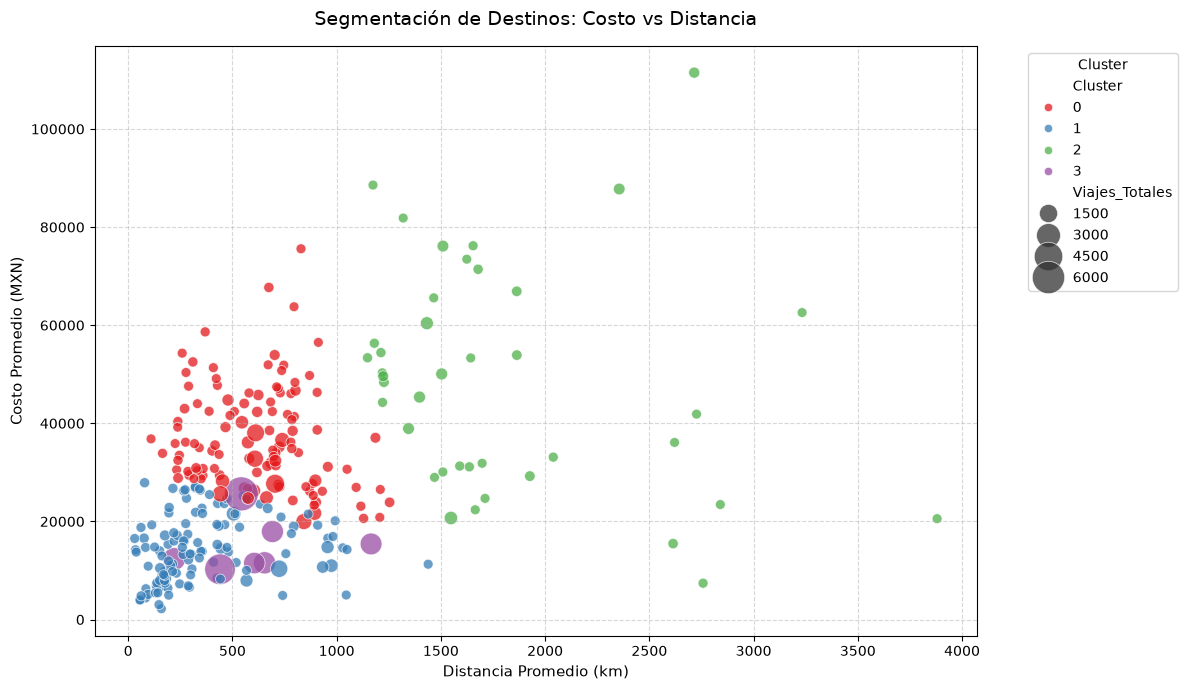

In [9]:
# 9. Agrupación y preparación de datos por Ciudad Destino
resumen_destinos = df_base.groupby('Destino').agg(
    Viajes_Totales=('ID_VIAJE', 'count'),
    Costo_Promedio=('Costo', 'mean'),
    Distancia_Promedio=('Kilometros_Ruta', 'mean')
).reset_index()

resumen_destinos = resumen_destinos.dropna()

# 10. Escalamiento de variables y aplicación del modelo K-Means
scaler = StandardScaler()
variables_cluster = ['Viajes_Totales', 'Costo_Promedio', 'Distancia_Promedio']
datos_escalados = scaler.fit_transform(resumen_destinos[variables_cluster])

# Se configuran 4 clusters basándonos en tu output previo
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
resumen_destinos['Cluster'] = kmeans.fit_predict(datos_escalados)

# 11. Generación de tabla de resumen general
resumen_clusters = resumen_destinos.groupby('Cluster').agg(
    Ciudades=('Destino', 'count'),
    Viajes_Totales=('Viajes_Totales', 'sum'),
    Costo_Promedio=('Costo_Promedio', 'mean'),
    Distancia_Promedio=('Distancia_Promedio', 'mean')
).reset_index()

print("\n--- RESUMEN DE CLUSTERS DE DESTINO ---")
print(resumen_clusters.round(2).to_markdown(index=False))

# Muestreo de ciudades representativas por cluster
for c in range(4):
    ejemplos = resumen_destinos[resumen_destinos['Cluster'] == c]['Destino'].head(3).tolist()
    print(f"Cluster {c} (Ejemplos): {ejemplos}")
    
# 12. Visualización gráfica de los Clusters
plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=resumen_destinos, 
    x='Distancia_Promedio', 
    y='Costo_Promedio', 
    hue='Cluster', 
    size='Viajes_Totales',
    sizes=(50, 600),
    palette='Set1',
    alpha=0.75
)

plt.title('Segmentación de Destinos: Costo vs Distancia', fontsize=14, pad=15)
plt.xlabel('Distancia Promedio (km)', fontsize=11)
plt.ylabel('Costo Promedio (MXN)', fontsize=11)

# Ajuste de leyenda para no obstruir los datos
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Guardar y mostrar el gráfico
#plt.savefig('clusters_destino.png', dpi=300)
plt.show()

In [10]:
# 13. Integración de los clusters al dataframe original para análisis predictivos posteriores
df_base = df_base.merge(resumen_destinos[['Destino', 'Cluster']], on='Destino', how='left')

In [11]:
# Recrear el Clustering para la variable predictora
df = df.dropna(subset=['Costo', 'Peso_Programado', 'Destino', 'Kilometros_Ruta', 'FECHA_EGRESO'])

destinos = df.groupby('Destino').agg({'ID_VIAJE':'count', 'Costo':'mean', 'Kilometros_Ruta':'mean'}).reset_index()
X_c = StandardScaler().fit_transform(destinos[['ID_VIAJE', 'Costo', 'Kilometros_Ruta']])
destinos['Cluster_Destino'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_c)

# Borrar la columna vieja si ya existe para evitar el MergeError
if 'Cluster_Destino' in df.columns:
    df = df.drop(columns=['Cluster_Destino'])

df = df.merge(destinos[['Destino', 'Cluster_Destino']], on='Destino', how='left')

# Limpiar variables categóricas
mascara_portacintas = df['FAMILIA_CAMION_DESC'].astype(str).str.contains('PORTACINTA|BIG COIL', case=False, na=False)
df['Camion'] = np.where(mascara_portacintas, 'T3_S3_Portacintas', df['Nomenclatura_Inferida'])
df['Camion'] = df['Camion'].fillna('Otro')

# Partición Temporal Estricta
df['FECHA_EGRESO'] = pd.to_datetime(df['FECHA_EGRESO'])
df['Mes'] = df['FECHA_EGRESO'].dt.month
df = df.sort_values('FECHA_EGRESO')

# Verificar distribución de meses para hacer el split (Train: Ene-Ago, Val: Sep, Test: Oct-Dic)
train_mask = df['Mes'] <= 8
val_mask = df['Mes'] == 9
test_mask = df['Mes'] >= 10

if len(df[test_mask]) < 1000: # Si la data no abarca el año completo, usamos split por posición 75-10-15
    n = len(df)
    df_train = df.iloc[:int(n * 0.75)]
    df_val = df.iloc[int(n * 0.75):int(n * 0.85)]
    df_test = df.iloc[int(n * 0.85):]
else:
    df_train = df[train_mask]
    df_val = df[val_mask]
    df_test = df[test_mask]

# 5. Configurar Pipeline de Scikit-Learn
features = ['Peso_Programado', 'Kilometros_Ruta', 'Cluster_Destino', 'Camion', 'PLANTA_ORIGEN']
target = 'Costo'

X_train, y_train = df_train[features], df_train[target]
X_val, y_val = df_val[features], df_val[target]
X_test, y_test = df_test[features], df_test[target]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Peso_Programado', 'Kilometros_Ruta']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['Camion', 'PLANTA_ORIGEN', 'Cluster_Destino'])
    ])

# Instanciar Random Forest (Controlando profundidad para evitar sobreajuste en nodos terminales)
rf = RandomForestRegressor(n_estimators=150, max_depth=15, min_samples_leaf=4, random_state=42, n_jobs=-1)
pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', rf)])

# 6. Entrenamiento y Predicción
pipeline.fit(X_train, y_train)
preds_val = pipeline.predict(X_val)
preds_test = pipeline.predict(X_test)

# 7. Evaluación
r2 = r2_score(y_test, preds_test)
rmse = np.sqrt(mean_squared_error(y_test, preds_test))

costo_real_test = y_test.sum()
costo_pred_test = preds_test.sum()
diferencia_pct = ((costo_pred_test - costo_real_test) / costo_real_test) * 100

print(f"Set de Entrenamiento: {len(X_train):,} viajes")
print(f"Set de Validación:    {len(X_val):,} viajes")
print(f"Set de Prueba (Test): {len(X_test):,} viajes")

print("\n--- MÉTRICAS DEL RANDOM FOREST (En Set de Prueba) ---")
print(f"R² (Varianza explicada): {r2:.4f}")
print(f"RMSE (Error promedio):   ${rmse:,.2f} MXN por viaje")

print("\n--- FASE 1: VALIDACIÓN FINANCIERA DE LA LÍNEA BASE ---")
print(f"Gasto Real en el periodo de Prueba:      ${costo_real_test/1e6:,.2f} Millones MXN")
print(f"Gasto Simulado (Suma de predicciones):   ${costo_pred_test/1e6:,.2f} Millones MXN")
print(f"Varianza del Simulador vs Realidad:      {diferencia_pct:+.2f}%")

Set de Entrenamiento: 28,291 viajes
Set de Validación:    3,772 viajes
Set de Prueba (Test): 5,659 viajes

--- MÉTRICAS DEL RANDOM FOREST (En Set de Prueba) ---
R² (Varianza explicada): 0.9427
RMSE (Error promedio):   $3,985.12 MXN por viaje

--- FASE 1: VALIDACIÓN FINANCIERA DE LA LÍNEA BASE ---
Gasto Real en el periodo de Prueba:      $127.75 Millones MXN
Gasto Simulado (Suma de predicciones):   $124.19 Millones MXN
Varianza del Simulador vs Realidad:      -2.78%


In [12]:
X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

# 2. Crear el PredefinedSplit (Train = -1, Val = 0) para respetar el tiempo
# Esto obliga al modelo a no mezclar el futuro con el pasado en el cross-validation
test_fold = np.concatenate([
    np.full(len(X_train), -1),  # -1 significa "usar solo para entrenar"
    np.zeros(len(X_val))        # 0 significa "usar para evaluar en la iteración"
])
ps = PredefinedSplit(test_fold)

# 3. Definir la malla de hiperparámetros (nota el prefijo 'model__' por el Pipeline)
param_dist = {
    'model__n_estimators': [100, 200, 300, 400],
    'model__max_depth': [10, 15, 20, 25, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [2, 4, 8],
    'model__max_features': ['sqrt', 'log2', None]
}

# 4. Configurar la Búsqueda Aleatoria (RandomizedSearchCV)
# Usaremos 20 iteraciones para no saturar tu memoria RAM
random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring='neg_root_mean_squared_error',
    cv=ps,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

# 5. Ejecutar el Fine-Tuning
print("Iniciando búsqueda de hiperparámetros...")
random_search.fit(X_train_val, y_train_val)

# 6. Extraer el mejor modelo y evaluar en el set de Prueba (Oct-Dic)
best_pipeline = random_search.best_estimator_
preds_test_best = best_pipeline.predict(X_test)

# Métricas finales
from sklearn.metrics import mean_squared_error, r2_score
r2_best = r2_score(y_test, preds_test_best)
rmse_best = np.sqrt(mean_squared_error(y_test, preds_test_best))

costo_real_test = y_test.sum()
costo_pred_test_best = preds_test_best.sum()
dif_pct_best = ((costo_pred_test_best - costo_real_test) / costo_real_test) * 100

print("\n=== RESULTADOS DEL FINE-TUNING ===")
print("Mejores Hiperparámetros encontrados:")
for param, value in random_search.best_params_.items():
    print(f" - {param}: {value}")

print("\n--- MÉTRICAS DEL RANDOM FOREST AFINADO (En Set de Prueba) ---")
print(f"R²: {r2_best:.4f}")
print(f"RMSE: ${rmse_best:,.2f} MXN por viaje")
print(f"Varianza Financiera Simulada vs Realidad: {dif_pct_best:+.2f}%")

Iniciando búsqueda de hiperparámetros...
Fitting 1 folds for each of 20 candidates, totalling 20 fits

=== RESULTADOS DEL FINE-TUNING ===
Mejores Hiperparámetros encontrados:
 - model__n_estimators: 400
 - model__min_samples_split: 2
 - model__min_samples_leaf: 4
 - model__max_features: None
 - model__max_depth: 15

--- MÉTRICAS DEL RANDOM FOREST AFINADO (En Set de Prueba) ---
R²: 0.9463
RMSE: $3,858.23 MXN por viaje
Varianza Financiera Simulada vs Realidad: -2.58%


In [13]:
xgb_model = xgb.XGBRegressor(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# Reutilizamos el 'preprocessor' del bloque anterior
pipeline_xgb = Pipeline(steps=[('preprocessor', preprocessor), ('model', xgb_model)])

print("Entrenando XGBoost con datos de Ene-Sep...")
pipeline_xgb.fit(X_train, y_train)

# Predicción exclusiva en el set de Prueba (Oct-Dic)
preds_test_xgb = pipeline_xgb.predict(X_test)

# Evaluación
r2_xgb = r2_score(y_test, preds_test_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, preds_test_xgb))

costo_pred_test_xgb = preds_test_xgb.sum()
dif_pct_xgb = ((costo_pred_test_xgb - costo_real_test) / costo_real_test) * 100

print("\n--- MÉTRICAS DE XGBOOST (En Set de Prueba) ---")
print(f"R²: {r2_xgb:.4f}")
print(f"RMSE: ${rmse_xgb:,.2f} MXN por viaje")
print(f"Gasto Simulado (XGBoost): ${costo_pred_test_xgb/1e6:,.2f} Millones MXN")
print(f"Varianza Financiera Simulada vs Realidad: {dif_pct_xgb:+.2f}%")

Entrenando XGBoost con datos de Ene-Sep...

--- MÉTRICAS DE XGBOOST (En Set de Prueba) ---
R²: 0.9387
RMSE: $4,124.15 MXN por viaje
Gasto Simulado (XGBoost): $123.79 Millones MXN
Varianza Financiera Simulada vs Realidad: -3.10%


In [14]:
# 1. Clonar el set de prueba (Octubre - Diciembre) para no alterar el original
X_test_opt = X_test.copy()
X_test_opt['Camion_Historico'] = X_test_opt['Camion']

# 2. Definir límite físico legal con holgura (30.4 toneladas)
limite_2_ejes_kg = 30400

# 3. Aplicar Motor Físico de Optimización (Right-Sizing) usando los nombres correctos
# A. Bajar cargas de 3 Ejes a 2 Ejes (Ahorro)
mascara_ahorro = (X_test_opt['Camion'] == 'T3-S3 (3 Ejes)') & (X_test_opt['Peso_Programado'] <= limite_2_ejes_kg)
X_test_opt.loc[mascara_ahorro, 'Camion'] = 'T3-S2 (2 Ejes)'

# B. Subir cargas de 2 Ejes a 3 Ejes (Mitigación de Riesgo / Compliance)
mascara_riesgo = (X_test_opt['Camion'] == 'T3-S2 (2 Ejes)') & (X_test_opt['Peso_Programado'] > limite_2_ejes_kg)
X_test_opt.loc[mascara_riesgo, 'Camion'] = 'T3-S3 (3 Ejes)'

# 4. Motor Financiero: Re-cotizar el trimestre usando el Random Forest
costos_optimizados = best_pipeline.predict(X_test_opt.drop(columns=['Camion_Historico']))

# 5. Calcular Impactos
viajes_optimizados_ahorro = mascara_ahorro.sum()
viajes_mitigados_riesgo = mascara_riesgo.sum()

costo_base_simulado = preds_test_best.sum()       # Lo que predijo que costaría originalmente (Línea Base)
costo_nuevo_simulado = costos_optimizados.sum()   # Lo que cuesta con la nueva política
ahorro_neto = costo_base_simulado - costo_nuevo_simulado
porcentaje_ahorro = (ahorro_neto / costo_base_simulado) * 100

print("=== FASE 2: RESULTADOS DE LA SIMULACIÓN DE RIGHT-SIZING (Q4 2026) ===")
print(f"Viajes reasignados a 2 Ejes (Ahorro):           {viajes_optimizados_ahorro:,} viajes")
print(f"Viajes reasignados a 3 Ejes (Gestión de Riesgo):{viajes_mitigados_riesgo:,} viajes")
print("-" * 65)
print(f"Gasto Trimestral Proyectado (Línea Base):       ${costo_base_simulado/1e6:,.2f} Millones MXN")
print(f"Gasto Trimestral Optimizado (Right-Sizing):     ${costo_nuevo_simulado/1e6:,.2f} Millones MXN")
print("-" * 65)
print(f"AHORRO NETO COMPROBADO:                         ${ahorro_neto/1e6:,.2f} Millones MXN")
print(f"REDUCCIÓN DEL PRESUPUESTO LOGÍSTICO (Trimestral):{porcentaje_ahorro:.2f}%")

=== FASE 2: RESULTADOS DE LA SIMULACIÓN DE RIGHT-SIZING (Q4 2026) ===
Viajes reasignados a 2 Ejes (Ahorro):           1,420 viajes
Viajes reasignados a 3 Ejes (Gestión de Riesgo):3 viajes
-----------------------------------------------------------------
Gasto Trimestral Proyectado (Línea Base):       $124.45 Millones MXN
Gasto Trimestral Optimizado (Right-Sizing):     $123.34 Millones MXN
-----------------------------------------------------------------
AHORRO NETO COMPROBADO:                         $1.11 Millones MXN
REDUCCIÓN DEL PRESUPUESTO LOGÍSTICO (Trimestral):0.89%


Iniciando Bootstrap Predictivo con 1000 simulaciones (remuestreando 685 rutas)...


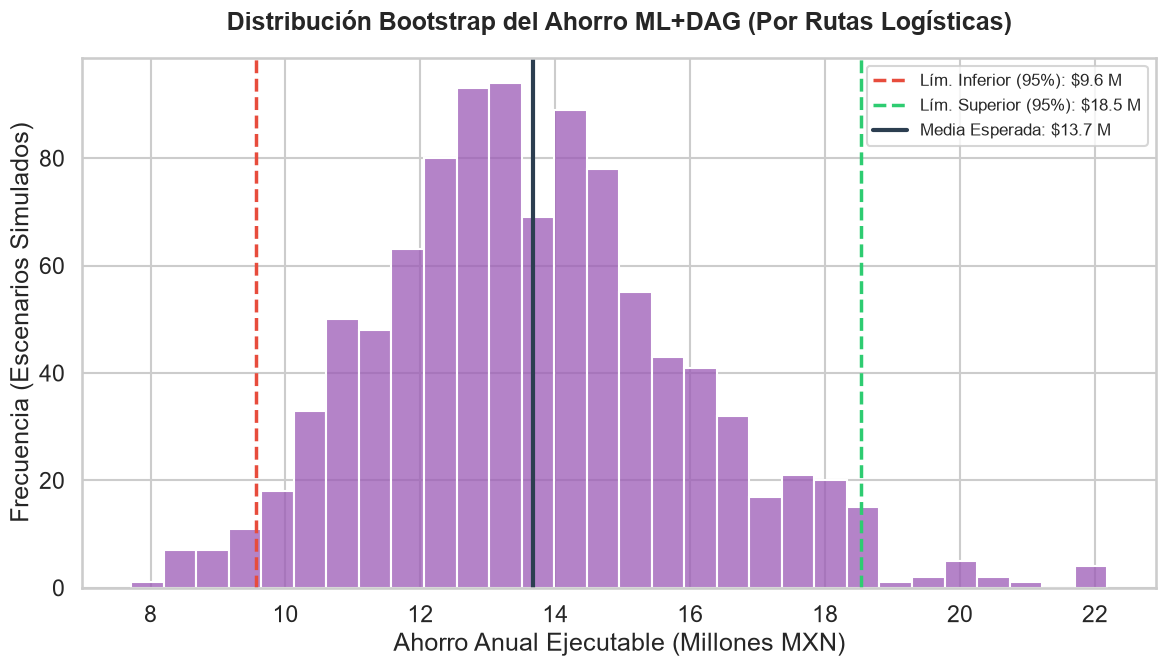

--- RESULTADOS DEL BOOTSTRAP PREDICTIVO (ML + DAG) ---
>> Intervalo de Confianza (95%): $9.56 M a $18.53 M MXN.
>> Ahorro Anual Esperado: $13.67 Millones de MXN.


In [15]:
# Preparar el dataset completo para proyectar el año
df_sim = df.copy()
df_sim['Ruta_ID'] = df_sim['PLANTA_ORIGEN'] + " - " + df_sim['Destino']
df_sim['Ahorro_Ejecutable'] = 0.0

# MOTOR FÍSICO Y CAUSAL (Reglas estrictas del DAG)
# A) Encontrar viajes ineficientes (3 Ejes que caben en 2 Ejes)
candidatos_ahorro = (df_sim['Camion'] == 'T3-S3 (3 Ejes)') & (df_sim['Peso_Programado'] <= 30400)
df_ahorro = df_sim[candidatos_ahorro].copy()
df_ahorro['Camion'] = 'T3-S2 (2 Ejes)' # Aplicar política

# Predecir costo exacto con Random Forest
costos_optimos = best_pipeline.predict(df_ahorro)
df_ahorro['Ahorro_ML'] = df_ahorro['Costo'] - costos_optimos

# Filtro financiero: Solo ejecutar si el ahorro es real (positivo)
df_ahorro['Ahorro_ML'] = df_ahorro['Ahorro_ML'].clip(lower=0)
df_sim.loc[candidatos_ahorro, 'Ahorro_Ejecutable'] = df_ahorro['Ahorro_ML']

# B) Mitigación de Riesgo (2 Ejes sobrecargados que deben subir a 3 Ejes)
candidatos_riesgo = (df_sim['Camion'] == 'T3-S2 (2 Ejes)') & (df_sim['Peso_Programado'] > 30400)
df_riesgo = df_sim[candidatos_riesgo].copy()
df_riesgo['Camion'] = 'T3-S3 (3 Ejes)' # Aplicar compliance

costos_riesgo = best_pipeline.predict(df_riesgo)
df_riesgo['Sobrecosto'] = costos_riesgo - df_riesgo['Costo']
# Restar este sobrecosto del ahorro total
df_sim.loc[candidatos_riesgo, 'Ahorro_Ejecutable'] = -df_riesgo['Sobrecosto'].clip(lower=0)

# 3. MOTOR DE BOOTSTRAP POR CONGLOMERADOS (Ruta_ID)
ahorro_por_ruta = df_sim.groupby('Ruta_ID')['Ahorro_Ejecutable'].sum()

B = 1000
ahorros_totales = []
rutas_unicas = df_sim['Ruta_ID'].unique()
n_clusters = len(rutas_unicas)

print(f"Iniciando Bootstrap Predictivo con {B} simulaciones (remuestreando {n_clusters} rutas)...")
np.random.seed(42)

for _ in range(B):
    rutas_muestra = np.random.choice(rutas_unicas, size=n_clusters, replace=True)
    rutas_counts = pd.Series(rutas_muestra).value_counts()
    suma_iteracion = sum(ahorro_por_ruta.get(ruta, 0) * conteo for ruta, conteo in rutas_counts.items())
    ahorros_totales.append(suma_iteracion)

# 4. MÉTRICAS Y VISUALIZACIÓN
ahorros_millones = np.array(ahorros_totales) / 1e6
limite_inf = np.percentile(ahorros_millones, 2.5)
limite_sup = np.percentile(ahorros_millones, 97.5)
media_boot = np.mean(ahorros_millones)

plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid", context="talk")
sns.histplot(ahorros_millones, bins=30, color='#9b59b6', edgecolor='white')

plt.axvline(limite_inf, color='#e74c3c', linestyle='--', linewidth=2.5, label=f'Lím. Inferior (95%): ${limite_inf:.1f} M')
plt.axvline(limite_sup, color='#2ecc71', linestyle='--', linewidth=2.5, label=f'Lím. Superior (95%): ${limite_sup:.1f} M')
plt.axvline(media_boot, color='#2c3e50', linestyle='-', linewidth=3, label=f'Media Esperada: ${media_boot:.1f} M')

plt.title('Distribución Bootstrap del Ahorro ML+DAG (Por Rutas Logísticas)', fontweight='bold', pad=20, fontsize=18)
plt.xlabel('Ahorro Anual Ejecutable (Millones MXN)')
plt.ylabel('Frecuencia (Escenarios Simulados)')
plt.legend(frameon=True, fontsize=12)
plt.tight_layout()
plt.show()

print("--- RESULTADOS DEL BOOTSTRAP PREDICTIVO (ML + DAG) ---")
print(f">> Intervalo de Confianza (95%): ${limite_inf:.2f} M a ${limite_sup:.2f} M MXN.")
print(f">> Ahorro Anual Esperado: ${media_boot:.2f} Millones de MXN.")